# RAG Chunking Strategy Comparison

This notebook compares **Character-based chunking** and **Token-based chunking** for a PDF document.

We will test six configurations:

| Chunking method | Chunk sizes | Overlap |
|---|---|---:|
| Character | 300, 500, 900 characters | 50 |
| Token | 300, 500, 900 tokens | 50 |

For a fair comparison, we keep the PDF, embedding model, evaluation questions, and `top_k` value the same.

At the end, the notebook displays a comparison table and charts the retrieval hit rate.


## 1. Install and import libraries

Run this cell once if the packages are not already installed.


In [2]:
%pip install -q chromadb sentence-transformers langchain-text-splitters pypdf pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import re
import chromadb
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from pypdf import PdfReader
from sentence_transformers import SentenceTransformer
from langchain_text_splitters import CharacterTextSplitter, TokenTextSplitter

print("Libraries imported successfully.")

c:\Users\KeerthanaV\Desktop\Projects\rag_app\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Libraries imported successfully.


## 2. Load and extract text from the PDF

Place your PDF in the `uploads` folder, or change `PDF_PATH` to the correct file location.

This cell uses `pypdf` to extract the text. If you already have your own `extract_pdf_text()` function, you can use that instead.


In [4]:
PDF_PATH = "uploads/Python Tutorial.pdf"

def extract_pdf_text(pdf_path):
    reader = PdfReader(pdf_path)
    pages = []

    for page in reader.pages:
        page_text = page.extract_text() or ""
        pages.append(page_text)

    return "\n".join(pages)

text = extract_pdf_text(PDF_PATH)

if not text.strip():
    raise ValueError("No text was extracted. Check the PDF path or whether the PDF is scanned.")

print("PDF loaded:", PDF_PATH)
print("Total characters:", len(text))


PDF loaded: uploads/Python Tutorial.pdf
Total characters: 307970


## 3. Prepare the evaluation questions


The metric used here is **Retrieval Hit Rate**: a question counts as a hit if at least one expected keyword appears in the combined top-k retrieved chunks.




In [5]:
evaluation_set = [
    {
        "question": "What is Python?",
        "expected_answer": "Python is an easy to learn and powerful programming language.",
        "keywords": ["easy to learn", "powerful", "programming language"]
    },
    {
        "question": "Why is Python useful?",
        "expected_answer": "Python helps automate tasks and rapid application development.",
        "keywords": ["automate", "rapid application development"]
    },
    {
        "question": "What are the advantages of Python?",
        "expected_answer": "Python offers high-level data structures, object-oriented programming, and interpreted execution.",
        "keywords": ["high-level", "object-oriented", "interpreted"]
    },
    {
        "question": "What is the Python interpreter?",
        "expected_answer": "The interpreter executes Python code interactively or from scripts.",
        "keywords": ["interpreter", "execute", "scripts"]
    },
    {
        "question": "What is interactive mode?",
        "expected_answer": "Interactive mode allows commands to be executed immediately from the prompt.",
        "keywords": ["interactive", "prompt", "commands"]
    },
    {
        "question": "What encoding is used by default in Python source files?",
        "expected_answer": "UTF-8.",
        "keywords": ["UTF-8"]
    },
    {
        "question": "What is floor division?",
        "expected_answer": "Floor division uses // and discards the fractional part.",
        "keywords": ["//", "fractional part"]
    },
    {
        "question": "How do you calculate powers in Python?",
        "expected_answer": "The ** operator is used for exponentiation.",
        "keywords": ["**", "power"]
    },
    {
        "question": "What error occurs when an undefined variable is used?",
        "expected_answer": "NameError.",
        "keywords": ["NameError"]
    },
    {
        "question": "How are strings created in Python?",
        "expected_answer": "Strings can be enclosed in single or double quotes.",
        "keywords": ["single quotes", "double quotes"]
    },
    {
        "question": "What is string slicing?",
        "expected_answer": "Slicing extracts a portion of a string using index ranges.",
        "keywords": ["slice", "substring"]
    },
    {
        "question": "Why are strings immutable?",
        "expected_answer": "String contents cannot be modified after creation.",
        "keywords": ["immutable", "cannot be changed"]
    },
    {
        "question": "What is a list in Python?",
        "expected_answer": "A mutable sequence used to store collections of values.",
        "keywords": ["mutable", "sequence"]
    },
    {
        "question": "What does append() do?",
        "expected_answer": "Adds an element to the end of a list.",
        "keywords": ["append", "end of list"]
    },
    {
        "question": "What is the difference between mutable and immutable objects?",
        "expected_answer": "Mutable objects can be modified while immutable objects cannot.",
        "keywords": ["mutable", "immutable"]
    },
    {
        "question": "How does a while loop work?",
        "expected_answer": "It executes while a condition remains true.",
        "keywords": ["while", "condition"]
    },
    {
        "question": "What is an if statement used for?",
        "expected_answer": "Conditional execution of code.",
        "keywords": ["condition", "branching"]
    },
    {
        "question": "How does a for loop work in Python?",
        "expected_answer": "It iterates over items in a sequence.",
        "keywords": ["iterate", "sequence"]
    },
    {
        "question": "What is the purpose of range()?",
        "expected_answer": "Generate a sequence of numbers.",
        "keywords": ["range", "sequence of numbers"]
    },
    {
        "question": "What does break do?",
        "expected_answer": "Terminates the nearest loop.",
        "keywords": ["break", "loop"]
    },
    {
        "question": "What does continue do?",
        "expected_answer": "Skips the remaining code and starts the next iteration.",
        "keywords": ["continue", "next iteration"]
    },
    {
        "question": "What is the pass statement?",
        "expected_answer": "A placeholder statement that performs no action.",
        "keywords": ["pass", "placeholder"]
    },
    {
        "question": "What is a function?",
        "expected_answer": "A reusable block of code defined using def.",
        "keywords": ["function", "def"]
    },
    {
        "question": "What is a docstring?",
        "expected_answer": "A string used to document a function, class, or module.",
        "keywords": ["docstring", "documentation"]
    },
    {
        "question": "What are default arguments?",
        "expected_answer": "Arguments that have predefined values.",
        "keywords": ["default argument"]
    },
    {
        "question": "What are keyword arguments?",
        "expected_answer": "Arguments passed using parameter names.",
        "keywords": ["keyword argument"]
    },
    {
        "question": "What is a lambda function?",
        "expected_answer": "A small anonymous function created with lambda.",
        "keywords": ["lambda", "anonymous function"]
    },
    {
        "question": "What is a tuple?",
        "expected_answer": "An immutable sequence of values.",
        "keywords": ["tuple", "immutable"]
    },
    {
        "question": "What is a set?",
        "expected_answer": "An unordered collection of unique elements.",
        "keywords": ["set", "unique"]
    },
    {
        "question": "What is a dictionary?",
        "expected_answer": "A collection of key-value pairs.",
        "keywords": ["dictionary", "key", "value"]
    }
]



## 4. Load the embedding model and configure experiments

We use the same SentenceTransformer model for every experiment.

**Important:** a chunk size of 300 characters is not equivalent to 300 tokens. The units are different, so interpret the results with that in mind.


In [6]:
MODEL_NAME = "all-MiniLM-L6-v2"
CHUNK_SIZES = [300, 500, 900]
CHUNK_OVERLAP = 50
TOP_K = 3
DB_PATH = "./chroma_db_chunking_comparison"

model = SentenceTransformer(MODEL_NAME)

print("Embedding model loaded:", MODEL_NAME)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2906.03it/s]


Embedding model loaded: all-MiniLM-L6-v2


## 5. Create chunks using each method

This notebook tests:

1. `CharacterTextSplitter` — splits using character length.
2. `TokenTextSplitter` — splits using token count.

The same overlap value is used in each experiment. Each configuration gets its own ChromaDB collection.


In [7]:
def create_chunks(document_text, method, chunk_size, chunk_overlap=50):
    if method == "character":
        splitter = CharacterTextSplitter(
            separator="\n",
            chunk_size=chunk_size,
            chunk_overlap=chunk_overlap,
            length_function=len,
            is_separator_regex=False
        )
    elif method == "token":
        splitter = TokenTextSplitter(
            chunk_size=chunk_size,
            chunk_overlap=chunk_overlap
        )
    else:
        raise ValueError("method must be 'character' or 'token'")

    return splitter.split_text(document_text)


for method in ["character", "token"]:
    for size in CHUNK_SIZES:
        preview_chunks = create_chunks(text, method, size, CHUNK_OVERLAP)
        print(f"{method.title()} | size={size} | chunks={len(preview_chunks)}")

Character | size=300 | chunks=1253
Character | size=500 | chunks=687
Character | size=900 | chunks=363
Token | size=300 | chunks=338
Token | size=500 | chunks=188
Token | size=900 | chunks=100


## 6. Store chunks in ChromaDB

This function creates a separate collection for each method and chunk size.

If you rerun an experiment, the existing collection with the same name is cleared first so old and new chunks are not mixed.


In [8]:
client = chromadb.PersistentClient(path=DB_PATH)

def build_collection(method, chunk_size):
    chunks = create_chunks(text, method, chunk_size, CHUNK_OVERLAP)

    if not chunks:
        raise ValueError(f"No chunks created for {method}, size {chunk_size}.")

    collection_name = f"pdf_{method}_{chunk_size}"

    # Remove the old collection for this exact configuration, if present
    existing_names = [c.name for c in client.list_collections()]
    if collection_name in existing_names:
        client.delete_collection(name=collection_name)

    collection = client.create_collection(name=collection_name)

    embeddings = model.encode(
        chunks,
        convert_to_numpy=True,
        show_progress_bar=True
    )

    ids = [f"chunk_{i}" for i in range(len(chunks))]

    collection.add(
        ids=ids,
        documents=chunks,
        embeddings=embeddings.tolist()
    )

    return collection, len(chunks)


print("ChromaDB client ready.")

ChromaDB client ready.


## 7. Evaluate retrieval performance

For every evaluation question:

1. Generate the question embedding.
2. Retrieve the top `TOP_K` chunks.
3. Check whether any expected keyword appears in the retrieved text.
4. Count it as a hit if at least one keyword is found.

`Retrieval Hit Rate = (Number of hit questions / Total questions) × 100`

This is a simple keyword-based retrieval metric. It is not the same as generated-answer accuracy or a human relevance judgement.


In [9]:
def evaluate_collection(collection, evaluation_items, embedding_model, top_k=3):
    hits = 0
    details = []

    for item in evaluation_items:
        question = item["question"]
        keywords = item["keywords"]

        query_embedding = embedding_model.encode(
            question,
            convert_to_numpy=True
        )

        results = collection.query(
            query_embeddings=[query_embedding.tolist()],
            n_results=min(top_k, collection.count())
        )

        retrieved_documents = results["documents"][0] if results["documents"] else []
        retrieved_text = " ".join(retrieved_documents).lower()

        matched_keywords = [
            keyword for keyword in keywords
            if keyword.lower() in retrieved_text
        ]

        is_hit = len(matched_keywords) > 0
        hits += int(is_hit)

        details.append({
            "question": question,
            "hit": is_hit,
            "matched_keywords": ", ".join(matched_keywords),
            "top_chunk_preview": retrieved_documents[0][:300] if retrieved_documents else ""
        })

    hit_rate = (hits / len(evaluation_items)) * 100 if evaluation_items else 0

    return hit_rate, hits, details


print("Evaluation function ready.")

Evaluation function ready.


## 8. Run all six experiments

This cell builds each collection, evaluates it with the same questions, and saves the results.

Depending on PDF size and your computer, embedding all configurations may take a little time.


In [ ]:
summary_results = []
all_evaluation_details = {}

for method in ["character", "token"]:
    for size in CHUNK_SIZES:
        print("\n" + "=" * 65)
        print(f"Running: {method.upper()} | chunk size: {size}")
        print("=" * 65)

        collection, total_chunks = build_collection(method, size)

        hit_rate, correct_retrievals, details = evaluate_collection(
            collection=collection,
            evaluation_items=evaluation_set,
            embedding_model=model,
            top_k=TOP_K
        )

        config_name = f"{method}_{size}"
        all_evaluation_details[config_name] = details

        summary_results.append({
            "Method": method.title(),
            "Chunk Size": size,
            "Unit": "characters" if method == "character" else "tokens",
            "Overlap": CHUNK_OVERLAP,
            "Total Chunks": total_chunks,
            "Correct Retrievals": correct_retrievals,
            "Total Questions": len(evaluation_set),
            "Retrieval Hit Rate (%)": round(hit_rate, 2)
        })

        print(f"Total chunks: {total_chunks}")
        print(f"Correct retrievals: {correct_retrievals}/{len(evaluation_set)}")
        print(f"Retrieval hit rate: {hit_rate:.2f}%")

print("\nAll experiments completed.")


Running: CHARACTER | chunk size: 300


Batches: 100%|██████████| 40/40 [00:19<00:00,  2.09it/s]


Total chunks: 1253
Correct retrievals: 24/30
Retrieval hit rate: 80.00%

Running: CHARACTER | chunk size: 500


Batches: 100%|██████████| 22/22 [00:20<00:00,  1.10it/s]


Total chunks: 687
Correct retrievals: 25/30
Retrieval hit rate: 83.33%

Running: CHARACTER | chunk size: 900


Batches: 100%|██████████| 12/12 [00:13<00:00,  1.15s/it]


... (3 outputs left out)

Batches: 100%|██████████| 6/6 [00:07<00:00,  1.19s/it]


Total chunks: 188
Correct retrievals: 26/30
Retrieval hit rate: 86.67%

Running: TOKEN | chunk size: 900


Batches: 100%|██████████| 4/4 [00:03<00:00,  1.04it/s]


Total chunks: 100
Correct retrievals: 26/30
Retrieval hit rate: 86.67%

All experiments completed.


## 9. Final comparison table

The table below compares all six configurations. The highest hit rate is shown first.

Check the total chunk count as well: a higher hit rate may come with more chunks and greater storage or indexing overhead.


In [11]:
comparison_df = pd.DataFrame(summary_results)

comparison_df = comparison_df.sort_values(
    by=["Retrieval Hit Rate (%)", "Total Chunks"],
    ascending=[False, True]
).reset_index(drop=True)

display(comparison_df)

best_result = comparison_df.iloc[0]
print("\nBest result by retrieval hit rate:")
print(
    f"{best_result['Method']} chunking, "
    f"size {best_result['Chunk Size']} {best_result['Unit']}, "
    f"hit rate {best_result['Retrieval Hit Rate (%)']:.2f}%"
)

,Method,Chunk Size,Unit,Overlap,Total Chunks,Correct Retrievals,Total Questions,Retrieval Hit Rate (%)
0,Token,300,tokens,50,338,27,30,90.00
1,Token,900,tokens,50,100,26,30,86.67
2,Token,500,tokens,50,188,26,30,86.67
3,Character,900,characters,50,363,26,30,86.67
4,Character,500,characters,50,687,25,30,83.33
5,Character,300,characters,50,1253,24,30,80.00



Best result by retrieval hit rate:
Token chunking, size 300 tokens, hit rate 90.00%


## 10. Visual comparison

This chart compares retrieval hit rate across the character and token configurations.


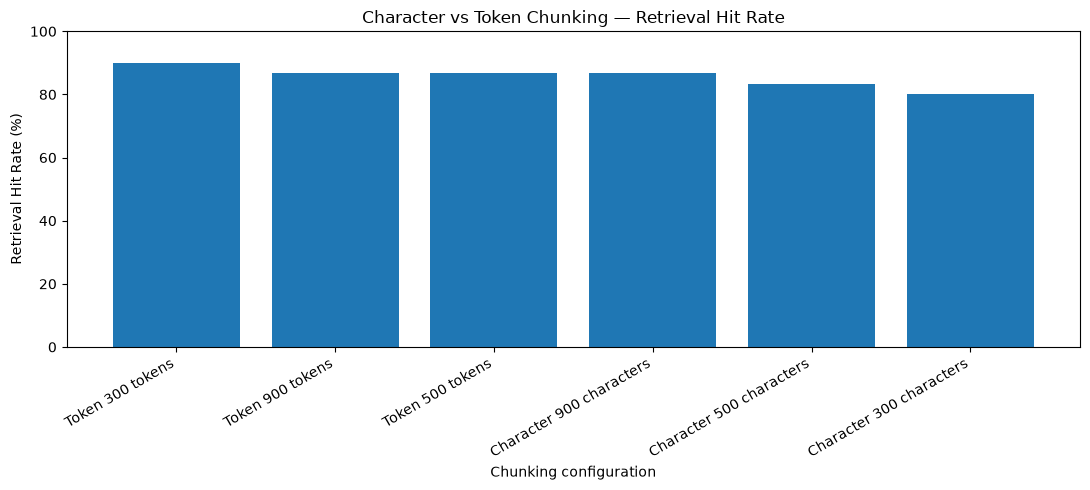

In [12]:
plot_df = comparison_df.copy()
plot_df["Configuration"] = (
    plot_df["Method"] + " " +
    plot_df["Chunk Size"].astype(str) + " " +
    plot_df["Unit"]
)

plt.figure(figsize=(11, 5))
plt.bar(
    plot_df["Configuration"],
    plot_df["Retrieval Hit Rate (%)"]
)
plt.ylabel("Retrieval Hit Rate (%)")
plt.xlabel("Chunking configuration")
plt.title("Character vs Token Chunking — Retrieval Hit Rate")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

## 11. Inspect question-level results

Use this cell to inspect which questions were retrieved successfully for a particular configuration.

Change `CONFIG_TO_INSPECT` to one of:
- `character_300`
- `character_500`
- `character_900`
- `token_300`
- `token_500`
- `token_900`


In [13]:
CONFIG_TO_INSPECT = "character_300"

details_df = pd.DataFrame(all_evaluation_details[CONFIG_TO_INSPECT])
display(details_df)

,question,hit,matched_keywords,top_chunk_preview
0,What is Python?,False,,Python enables programs to be written compactl...
1,Why is Python useful?,False,,"and tools, and additional documentation.\nThe ..."
2,What are the advantages of Python?,True,high-level,Python enables programs to be written compactl...
3,What is the Python interpreter?,True,interpreter,"and tools, and additional documentation.\nThe ..."
4,What is interactive mode?,True,"interactive, prompt, commands",interactively in the interpreter.\n... The def...
5,What encoding is used by default in Python sou...,True,UTF-8,"2.2.1 Source Code Encoding\nBy default, Python..."
6,What is floor division?,True,"//, fractional part","9\nPython Tutorial, Release 3.7.0\nDivision (/..."
7,How do you calculate powers in Python?,True,"**, power",5.666666666666667\n>>>\n>>> 17 // 3 # floor di...
8,What error occurs when an undefined variable i...,True,NameError,>>> height = 5 * 9\n>>> width * height\n900\nI...
9,How are strings created in Python?,False,,"from strings, is derived from the ﬁle of the s..."
